# Practical 5 - Probability and Hypothesis Testing
Dataset: Iris (sepal length of 150 flowers) + a delivery-time scenario for the Z-test

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
def find_data(name):
    """Look for the CSV in the usual places; in Colab, ask for an upload if it is missing."""
    folders = (HERE.parent / "Datasets", HERE / "Datasets", HERE, Path.cwd(),
               Path("/content"), Path("/content/Datasets"), Path("/content/drive/MyDrive"))
    for folder in folders:
        if (folder / name).exists():
            return folder
    try:
        from google.colab import files
        print(f"{name} not found - please choose it in the upload dialog (it is in the Datasets folder).")
        files.upload()
        return Path.cwd()
    except ImportError:
        raise FileNotFoundError(f"Could not find {name}. Put it in a 'Datasets' folder next to this script.")

DATA = find_data("iris.csv")
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

iris = pd.read_csv(DATA / "iris.csv")
sepal = iris["sepal_length"]
mu, sd = sepal.mean(), sepal.std(ddof=1)
print(f"Flowers measured      : {len(sepal)}")
print(f"Mean sepal length     : {mu:.4f} cm")
print(f"Sample std deviation  : {sd:.4f} cm")

Flowers measured      : 150
Mean sepal length     : 5.8433 cm
Sample std deviation  : 0.8281 cm


## Helper: theoretical (normal model) vs actual (observed) probability

In [2]:
def compare(lower=-np.inf, upper=np.inf):
    """P(lower < X < upper) under N(mu, sd) and as an observed proportion."""
    theory = norm.cdf(upper, mu, sd) - norm.cdf(lower, mu, sd)
    actual = ((sepal > lower) & (sepal < upper)).mean()
    return theory, actual

## Q1. P(sepal length > 6.5 cm)

In [3]:
z = (6.5 - mu) / sd
theory, actual = compare(lower=6.5)
print(f"z-score             : {z:.4f}")
print(f"Theoretical P(X>6.5): {theory:.4f}  ({theory:.2%})")
print(f"Observed    P(X>6.5): {actual:.4f}  ({actual:.2%})")
print(f"Difference          : {abs(theory - actual) * 100:.2f} percentage points")

z-score             : 0.7930
Theoretical P(X>6.5): 0.2139  (21.39%)
Observed    P(X>6.5): 0.2000  (20.00%)
Difference          : 1.39 percentage points


## Q2. P(5.0 < sepal length < 6.0 cm)

In [4]:
z_lo, z_hi = (5.0 - mu) / sd, (6.0 - mu) / sd
theory2, actual2 = compare(5.0, 6.0)
print(f"z-scores            : {z_lo:.4f} and {z_hi:.4f}")
print(f"Theoretical P       : {theory2:.4f}  ({theory2:.2%})")
print(f"Observed P          : {actual2:.4f}  ({actual2:.2%})")
print(f"Difference          : {abs(theory2 - actual2) * 100:.2f} percentage points")

z-scores            : -1.0184 and 0.1892
Theoretical P       : 0.4208  (42.08%)
Observed P          : 0.3400  (34.00%)
Difference          : 8.08 percentage points


## Q3. Two-tailed Z-test
A courier company claims an average delivery time of 32 minutes (known sigma = 6 min).
A sample of 45 recent deliveries averaged 30.4 minutes. Has the average changed (alpha = 0.05)?

In [5]:
def two_tailed_z_test(sample_mean, mu0, sigma, n, alpha=0.05):
    se = sigma / np.sqrt(n)
    z = (sample_mean - mu0) / se
    p = 2 * norm.sf(abs(z))
    crit = norm.ppf(1 - alpha / 2)
    ci = (sample_mean - crit * se, sample_mean + crit * se)
    return {"se": se, "z": z, "p": p, "crit": crit, "ci": ci, "reject": abs(z) > crit}

res = two_tailed_z_test(sample_mean=30.4, mu0=32, sigma=6, n=45)
print("H0: mean delivery time = 32 min   |   H1: mean delivery time != 32 min")
print(f"Standard error      : {res['se']:.4f}")
print(f"Z statistic         : {res['z']:.4f}")
print(f"Two-tailed p-value  : {res['p']:.4f}")
print(f"Critical values     : +/- {res['crit']:.4f}")
print(f"95% CI for the mean : ({res['ci'][0]:.2f}, {res['ci'][1]:.2f})")
print("Decision            :", "REJECT H0" if res["reject"] else "FAIL TO REJECT H0 - no significant change")

H0: mean delivery time = 32 min   |   H1: mean delivery time != 32 min
Standard error      : 0.8944
Z statistic         : -1.7889
Two-tailed p-value  : 0.0736
Critical values     : +/- 1.9600
95% CI for the mean : (28.65, 32.15)
Decision            : FAIL TO REJECT H0 - no significant change


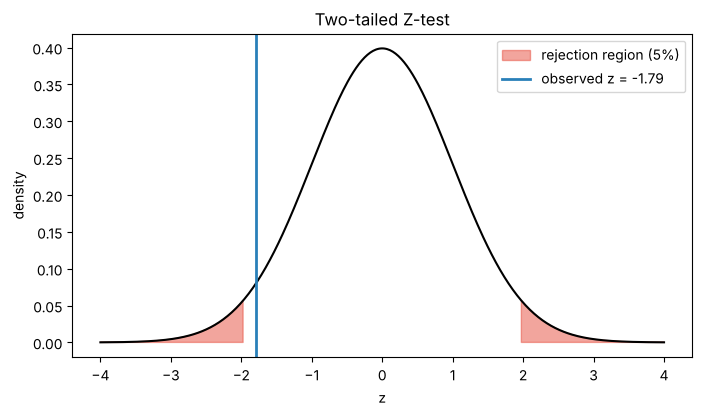

In [6]:
xs = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(xs, norm.pdf(xs), color="black")
ax.fill_between(xs, norm.pdf(xs), where=np.abs(xs) >= res["crit"], color="#e74c3c", alpha=0.5,
                label="rejection region (5%)")
ax.axvline(res["z"], color="#2980b9", linewidth=2, label=f"observed z = {res['z']:.2f}")
ax.set(title="Two-tailed Z-test", xlabel="z", ylabel="density")
ax.legend()
fig.savefig(FIG / "z_test.png", dpi=120, bbox_inches="tight")
plt.show()